# 03 - CNN trained from scratch

**Owner:** Jay Ervin - CSC 7333 Group 6

Rather than using HOG, a convolutional neural network can automatically extract features from an image. Below is a lightweight VGG-inspired CNN which we train from scratch on 48×48 images, with **no pretraining**. This demonstrates the additional benefit that can be gained from using a CNN, in comparison to a HOG+SVM classifier. Transfer learning is then added.

**Run on Colab with a GPU** (Runtime, then Change runtime type, then T4 GPU). On a T4 the whole notebook takes about 100 minutes, including the tuning runs. First, upload the `.npy` files to `MyDrive/ferplus/data`. Model weights and evaluation metrics are saved to `MyDrive/ferplus/`.

In [ ]:
import copy
import json
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2

IMAGE_SIZE = 48

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Place the 9 .npy files in MyDrive/ferplus/data. Model weights and metrics are saved to MyDrive/ferplus.
    try:
        drive.mount("/content/drive")
    except Exception as err:
        print("Could not mount Google Drive, so copy the .npy files to /content/data by hand:", err)
    DRIVE = Path("/content/drive/MyDrive/ferplus")
    DATA_DIR = Path("/content/data")
    DATA_DIR.mkdir(exist_ok=True)
    # As it is slow to retrieve large arrays from Drive, required files for this notebook are copied once. The
    # 48x48 data is always required as it is used to locate test images that are also in Train.
    for file in (DRIVE / "data").glob("*.npy"):
        needed = "labels" in file.name or "_48_" in file.name or f"_{IMAGE_SIZE}_" in file.name
        if needed and not (DATA_DIR / file.name).exists():
            shutil.copy(file, DATA_DIR)
    RESULTS_DIR, MODELS_DIR = DRIVE / "results", DRIVE / "models"
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR, RESULTS_DIR, MODELS_DIR = ROOT / "data", ROOT / "results", ROOT / "models"

FIG = RESULTS_DIR / "figures"
for folder in (FIG, RESULTS_DIR / "metrics", MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("data files:", sorted(p.name for p in DATA_DIR.glob("*.npy")))

Mounted at /content/drive
data: ['FER2013Test_48_images.npy', 'FER2013Test_labels.npy', 'FER2013Train_48_images.npy', 'FER2013Train_labels.npy', 'FER2013Valid_48_images.npy', 'FER2013Valid_labels.npy']


In [2]:
SEED = 42
CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


def compute_metrics(y_true, y_pred):
    # Accuracy, macro and class level statistics and a confusion matrix. Output is in the format that notebook 06
    # expects.
    labels = range(len(CLASSES))
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1.mean(),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "per_class": {name: {"precision": precision[i], "recall": recall[i], "f1": f1[i], "support": int(support[i])}
                      for i, name in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }

device: cuda | smoke test: False


## 1. Data

As with all models, the same splits are used and Disgust and Contempt have been excluded. Data augmentation is only used for the training data. This includes random horizontal flips, slight rotations, translations and scaling and also small changes to brightness and contrast. As the model contains around 5M parameters but is only trained on around 25k images, data augmentation is useful in preventing overfitting.

In [3]:
X_train, y_train = load_split("Train", IMAGE_SIZE)
X_valid, y_valid = load_split("Valid", IMAGE_SIZE)
X_test, y_test = load_split("Test", IMAGE_SIZE)
print("images:", len(X_train), len(X_valid), len(X_test))

# Test images that are identical to training images (see notebook 01).
train_bytes = {image.tobytes() for image in X_train}
in_train = np.array([image.tobytes() in train_bytes for image in X_test])


class FaceDataset(Dataset):
    # Images are retained as uint8. Each image is then transformed to a float tensor when it is loaded.
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        image = torch.from_numpy(self.images[i]).unsqueeze(0)
        return self.transform(image), int(self.labels[i])


normalize = v2.Normalize([0.5], [0.5])
# Random mirroring, rotation, translation and scaling plus adjustments to brightness and contrast. Only for
# training.
train_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.RandomHorizontalFlip(),
                       v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
                       v2.ColorJitter(brightness=0.2, contrast=0.2), normalize])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), normalize])

BATCH_SIZE = 128
loaders = {
    "train": DataLoader(FaceDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    "valid": DataLoader(FaceDataset(X_valid, y_valid, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
    "test": DataLoader(FaceDataset(X_test, y_test, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
}

# Inverse class frequency weighting. Errors for under-represented classes (for example, Fear) are therefore
# penalized more heavily.
class_weights = len(y_train) / (len(CLASSES) * np.bincount(y_train))
print("class weights:", dict(zip(CLASSES, class_weights.round(2).tolist())))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))

{'train': 24783, 'valid': 3140, 'test': 3103}
class weights: {'Neutral': np.float32(0.47), 'Happiness': np.float32(0.57), 'Surprise': np.float32(1.32), 'Sadness': np.float32(1.36), 'Anger': np.float32(2.01), 'Fear': np.float32(8.07)}


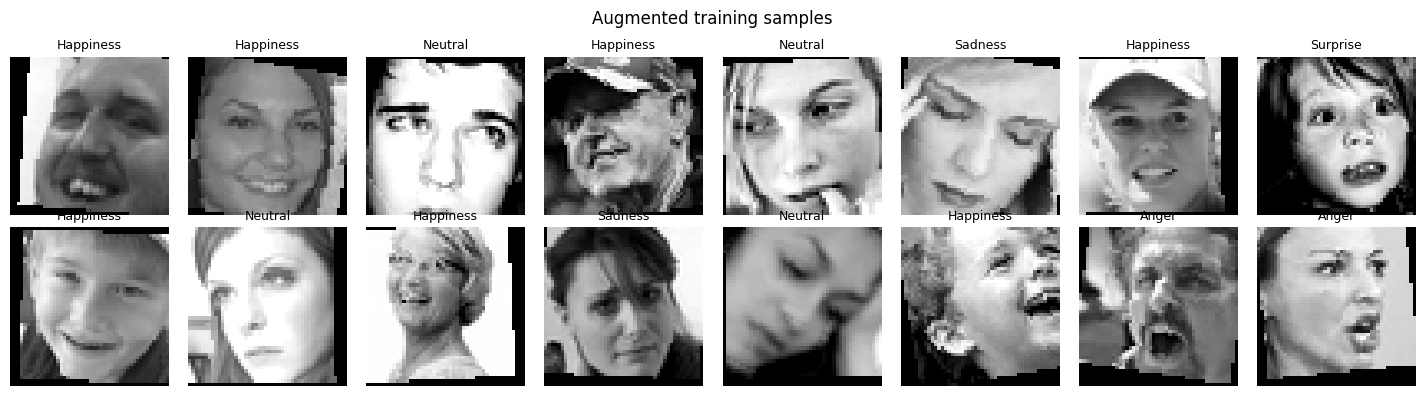

In [4]:
images, labels = next(iter(loaders["train"]))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, image, label in zip(axes.ravel(), images, labels):
    # Undoing the normalization allows the true gray levels of the face to be displayed.
    ax.imshow((image[0] * 0.5 + 0.5).clamp(0, 1), cmap="gray")
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training samples")
plt.tight_layout()
plt.show()

## 2. Architecture

There are four convolution modules. Each consists of two 3×3 convolutions, followed by batch normalization and ReLU. This is then followed by max pooling (2×2 kernel) and dropout. Image dimension is halved at each convolution module (48 to 24 to 12 to 6 to 3). The number of filters also doubles at each stage. Global average pooling and a small fully connected head are used to output the 6 class scores.

In [5]:
class ScratchCNN(nn.Module):
    # A VGG-type network for 48x48 grayscale faces. Each of the four sections halves the image size (48, 24, 12, 6,
    # 3) and doubles the number of filters. Global average pooling followed by a compact fully-connected section
    # produces the 6 class scores.
    def __init__(self, base_filters=64, dropout=0.4, block_dropout=0.25):
        super().__init__()
        blocks, in_ch = [], 1
        for out_ch in [base_filters, base_filters * 2, base_filters * 4, base_filters * 8]:
            blocks.append(nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout(block_dropout)))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_ch, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(256, len(CLASSES)))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


model = ScratchCNN(base_filters=64)
print(model)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

ScratchCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (7): Dropout(p=0.25, inplace=False)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps

## 3. Hyperparameter tuning

A small grid search is carried out for the learning rate, the dropout rate of the fully connected head and the network width. For each hyperparameter combination, a restricted number of epochs are trained. The best performing (in terms of macro F1 score on the validation data) hyperparameter set is selected. AdamW is used as the optimizer and the learning rate is halved once the validation F1 metric ceases to improve.

In [6]:
# Mixed precision approximately halves GPU training duration. However, it is disabled on the CPU.
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(model, loader, optimizer=None):
    # A single pass over a loader. If an optimizer is given, the model is trained. Otherwise, it is only evaluated.
    # Loss value, accuracy, macro F1 and predicted classes are returned.
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            y_true += y.tolist()
            y_pred += logits.argmax(1).tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return total_loss / len(y_true), (y_true == y_pred).mean(), f1_score(y_true, y_pred, average="macro"), y_pred


def fit(model, optimizer, scheduler, epochs, patience, history=None):
    # Early stopping is applied according to the validation macro F1. Best model weights are reloaded at the end of
    # training. An existing history can be supplied to continue the curves of an earlier stage.
    history = {} if history is None else history
    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc, _, _ = run_epoch(model, loaders["train"], optimizer)
        val_loss, val_acc, val_f1, _ = run_epoch(model, loaders["valid"])
        if scheduler is not None:
            scheduler.step(val_f1)
        values = {"train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc,
                  "val_macro_f1": val_f1, "lr": lr}
        for key, value in values.items():
            history.setdefault(key, []).append(float(value))
        print(f"epoch {epoch:3d} | train loss {train_loss:.4f} acc {train_acc:.3f} | val loss {val_loss:.4f} "
              f"acc {val_acc:.3f} f1 {val_f1:.3f} | lr {lr:.1e} | {time.time() - start:.0f}s")
        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"No improvement for {patience} epochs, stopping.")
                break
    model.load_state_dict(best_state)
    history["best_val_macro_f1"] = float(best_f1)
    return history


TUNING_EPOCHS = 15
grid = [
    {"lr": 1e-3, "dropout": 0.4, "base_filters": 64},
    {"lr": 3e-4, "dropout": 0.4, "base_filters": 64},
    {"lr": 1e-3, "dropout": 0.5, "base_filters": 64},
    {"lr": 1e-3, "dropout": 0.4, "base_filters": 32},
]


def train_config(params, epochs, patience):
    # An identical seed is used for all runs. This ensures like-for-like assessment of different configurations.
    torch.manual_seed(SEED)
    model = ScratchCNN(base_filters=params["base_filters"], dropout=params["dropout"]).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=1e-4)
    # The learning rate is halved if there is no improvement in the validation macro F1 for 3 epochs.
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    return model, fit(model, optimizer, scheduler, epochs, patience)


tuning = []
for params in grid:
    print("\n", params)
    _, history = train_config(params, TUNING_EPOCHS, patience=5)
    tuning.append({**params, "epochs run": len(history["val_macro_f1"]),
                   "best val macro F1": round(history["best_val_macro_f1"], 4)})

tuning = pd.DataFrame(tuning).sort_values("best val macro F1", ascending=False)
tuning


 {'lr': 0.001, 'dropout': 0.4, 'base_filters': 64}


train:   0%|          | 0/194 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580><function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
if w.is_alive():
    if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

    assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/lib/python3.13/multiprocessing/process.py", line 16

epoch   1 | train loss 1.7524 acc 0.235 | val loss 1.7608 acc 0.368 f1 0.210 | lr 1.0e-03 | 24s  *


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive


train:   0%|          | 0/194 [00:00<?, ?it/s]

... (176 outputs left out)

train:   0%|          | 0/194 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
: can only test a child process    
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in: <function _Multi

epoch  15 | train loss 0.7128 acc 0.722 | val loss 0.6496 acc 0.741 f1 0.664 | lr 1.0e-03 | 42s


,lr,dropout,base_filters,epochs run,best val macro F1
1,0.0003,0.4,64,15,0.7524
0,0.0010,0.4,64,15,0.7461
2,0.0010,0.5,64,15,0.7222
3,0.0010,0.4,32,15,0.6833


## 4. Final training

Further epochs are trained for the best hyperparameter set. Early stopping (patience = 10) is also used, again based on the macro F1 score across the validation data. Weights from the best epoch are retained.

In [7]:
best = tuning.iloc[0]
BEST = {"lr": float(best["lr"]), "dropout": float(best["dropout"]), "base_filters": int(best["base_filters"])}
EPOCHS = 60
print("final settings:", BEST)

start = time.time()
model, history = train_config(BEST, EPOCHS, patience=10)
train_time = time.time() - start
print(f"training time: {train_time / 60:.1f} min")

final settings: {'lr': 0.0003, 'dropout': 0.4, 'base_filters': 64}


train:   0%|          | 0/194 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
self._shutdown_workers()    
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    Exception ignored in:   File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7c966

epoch   1 | train loss 1.7328 acc 0.244 | val loss 1.5411 acc 0.377 f1 0.306 | lr 3.0e-04 | 44s  *


train:   0%|          | 0/194 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__


  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Traceback (most recent call last):
    self._shutdown_workers()      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in: if w.is_alive():
<function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>    
self._shutdown_workers()
  File

... (171 outputs left out)

epoch  59 | train loss 0.3619 acc 0.840 | val loss 0.4351 acc 0.839 f1 0.807 | lr 2.3e-06 | 42s


train:   0%|          | 0/194 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in:     if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError<function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>
: can only test a child processTraceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    Exception ignored in: self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7c966046d580>

Traceback (most recent call last):
  File "/usr/local/lib/pyt

epoch  60 | train loss 0.3660 acc 0.838 | val loss 0.4331 acc 0.840 f1 0.808 | lr 2.3e-06 | 44s
training time: 42.2 min


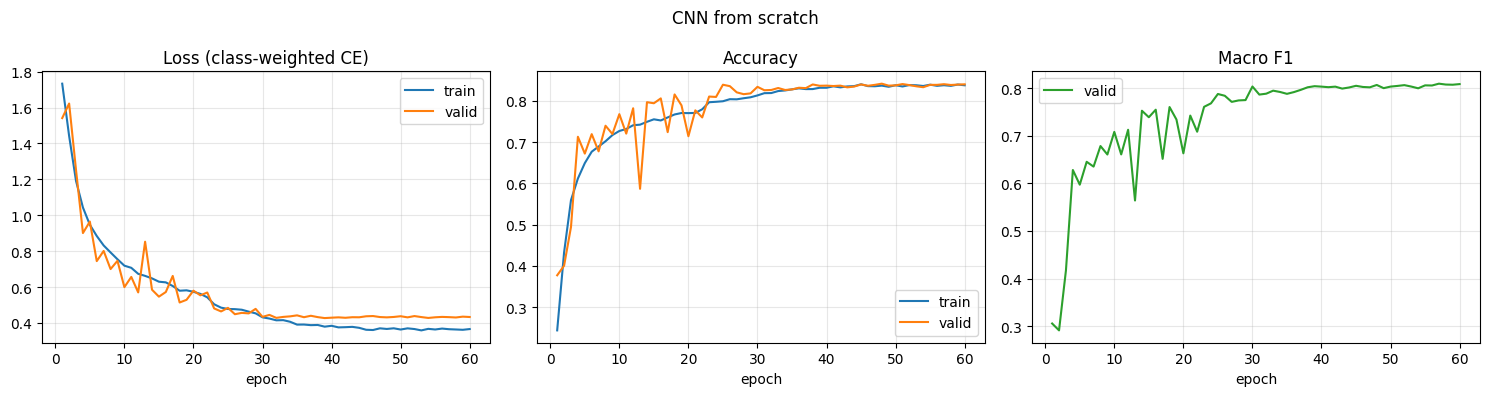

In [8]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="valid")
axes[0].set_title("Loss (class-weighted cross-entropy)")
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="valid")
axes[1].set_title("Accuracy")
axes[2].plot(epochs, history["val_macro_f1"], color="tab:green", label="valid")
axes[2].set_title("Macro F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
fig.suptitle("CNN from scratch")
fig.tight_layout()
fig.savefig(FIG / "cnn_scratch_curves.png", dpi=150)
plt.show()

## 5. Test results

In [9]:
start = time.time()
_, _, _, y_pred = run_epoch(model, loaders["test"])
ms_per_image = 1000 * (time.time() - start) / len(y_test)

test_metrics = compute_metrics(y_test, y_pred)
print(f"accuracy {test_metrics['accuracy']:.4f}, macro F1 {test_metrics['macro_f1']:.4f}")
print(pd.DataFrame(test_metrics["per_class"]).T.round(3))

# Same statistics but for test images not also present in the training data.
clean_metrics = compute_metrics(y_test[~in_train], y_pred[~in_train])
print(f"\nclean test subset ({(~in_train).sum()} images): accuracy {clean_metrics['accuracy']:.4f}, "
      f"macro F1 {clean_metrics['macro_f1']:.4f}")

accuracy  0.8356
macro F1  0.7904
class        prec recall     f1      n
Neutral     0.904  0.772  0.832   1081
Happiness   0.942  0.916  0.929    891
Surprise    0.826  0.887  0.855    400
Sadness     0.615  0.781  0.688    384
Anger       0.766  0.887  0.822    266
Fear        0.591  0.642  0.615     81

clean test subset (2874 images): accuracy 0.8302, macro F1 0.7807


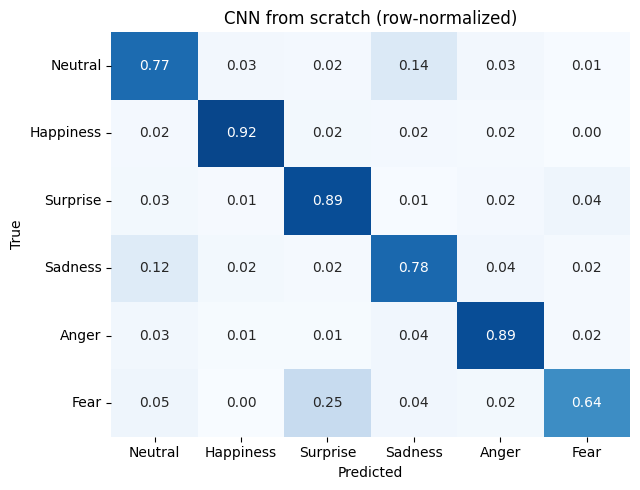

In [10]:
cm = np.array(test_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.5, 5))
# Each row is divided by its sum. Diagonal entries then indicate the recall for each class.
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(xlabel="Predicted", ylabel="True", title="CNN from scratch (row-normalized)")
plt.tight_layout()
fig.savefig(FIG / "cnn_scratch_confusion.png", dpi=150)
plt.show()

In [11]:
model_kwargs = {"base_filters": BEST["base_filters"], "dropout": BEST["dropout"]}
torch.save({"model_name": "cnn_scratch", "classes": CLASSES, "state_dict": model.state_dict(),
            "model_kwargs": model_kwargs}, MODELS_DIR / "cnn_scratch.pt")

metrics = {
    "model": "cnn_scratch",
    "test": test_metrics,
    "test_clean": clean_metrics,
    "val_macro_f1": history["best_val_macro_f1"],
    "hyperparameters": {**BEST, "batch_size": BATCH_SIZE, "optimizer": "AdamW", "weight_decay": 1e-4,
                        "scheduler": "ReduceLROnPlateau(0.5, patience 3)", "max_epochs": EPOCHS},
    "tuning": tuning.to_dict("records"),
    "history": history,
    "parameters": sum(p.numel() for p in model.parameters()),
    "train_time_sec": round(train_time, 1),
    "inference_ms_per_image": round(ms_per_image, 3),
    "device": str(device),
}
(RESULTS_DIR / "metrics" / "cnn_scratch.json").write_text(json.dumps(metrics, indent=2))

saved /content/drive/My Drive/LSU - Masters/CSC 7333/Final Project/results/metrics/cnn_scratch.json


## 6. Observations

_[To be completed following Colab training.] Contrast results to those obtained from HOG+SVM. Discuss training behavior (for example, overfitting and when early stopping was triggered). Note which classes had their performance enhanced._

> **After training on Colab:** download the JSON file of evaluation metrics (`MyDrive/ferplus/results/metrics/cnn_scratch.json`), together with the figures from `MyDrive/ferplus/results/figures/` and model weights file (`MyDrive/ferplus/models/cnn_scratch.pt`) into the corresponding folders within the repo. Add the JSON, the graphs and the model weights (the `.pt` file) to git.